# THIS IS BANK CUSTOMER CHURN PREDICTIONS

#### import necessary library


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# initiating google collab
from google.colab import files
uploaded = files.upload()

Saving Customer-Churn-Records.csv to Customer-Churn-Records (1).csv


# loading the data

In [ ]:
# loading our dataset
df = pd.read_csv('Customer-Churn-Records.csv')

In [ ]:
# printing the first  10 rows
df.head(10)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1,1,5,DIAMOND,484
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0,0,2,SILVER,206
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1,1,2,DIAMOND,282
8,9,15792365,He,501,France,Male,44,4,142051.07,2,0,1,74940.50,0,0,3,GOLD,251
9,10,15592389,H?,684,France,Male,27,2,134603.88,1,1,1,71725.73,0,0,3,GOLD,342


# data understanding

In [ ]:
# checking the shape of the data
df.shape

(10000, 18)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [ ]:
# checking the column names and datatypes
df.dtypes

,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64


In [ ]:
# checking the binary columns
binary_cols = [
    "HasCrCard",
    "IsActiveMember",
    "Exited",
    "Complain"]
for x in binary_cols:
  print(df[x].value_counts())

HasCrCard
1    7055
0    2945
Name: count, dtype: int64
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64
Exited
0    7962
1    2038
Name: count, dtype: int64
Complain
0    7956
1    2044
Name: count, dtype: int64


In [ ]:
# understanding basic statistics
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


## data cleaning

In [ ]:
#checking if there is missing values or duplicates
print(f"checking the sum of missing values \n {df.isnull().sum()}")


checking the sum of missing values 
 RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64


In [ ]:
print(f"checking if there is duplicate values values \n {df.duplicated().sum()}")

checking if there is duplicate values values 
 0


In [ ]:
# checking if there is an outlier
numerical_cols = ["CreditScore","Age","Balance","EstimatedSalary","Point Earned","Satisfaction Score"]

outlier_sum = []
for cols in numerical_cols:
  q1 = df[cols].quantile(0.25)
  q3 = df[cols].quantile(0.75)
  IQR = q3-q1

  lower = q1 - 1.5*IQR
  upper = q3 + 1.5*IQR
  N_outliers = ((df[cols]< lower) | (df[cols]>upper)).sum()

  outlier_sum.append({
    "colums": cols,
    "n_outliers": N_outliers,
    "lower boundary": lower,
    "upper boundary": upper
  })
outlier_df = pd.DataFrame(outlier_sum).set_index("colums")
print(outlier_df)
print(outlier_df.sum())


                    n_outliers  lower boundary  upper boundary
colums                                                        
CreditScore                 15       383.00000       919.00000
Age                        359        14.00000        62.00000
Balance                      0   -191466.36000    319110.60000
EstimatedSalary              0    -96577.09625    296967.45375
Point Earned                 0      -176.50000      1387.50000
Satisfaction Score           0        -1.00000         7.00000
n_outliers           374.00000
lower boundary   -287823.95625
upper boundary    618453.55375
dtype: float64


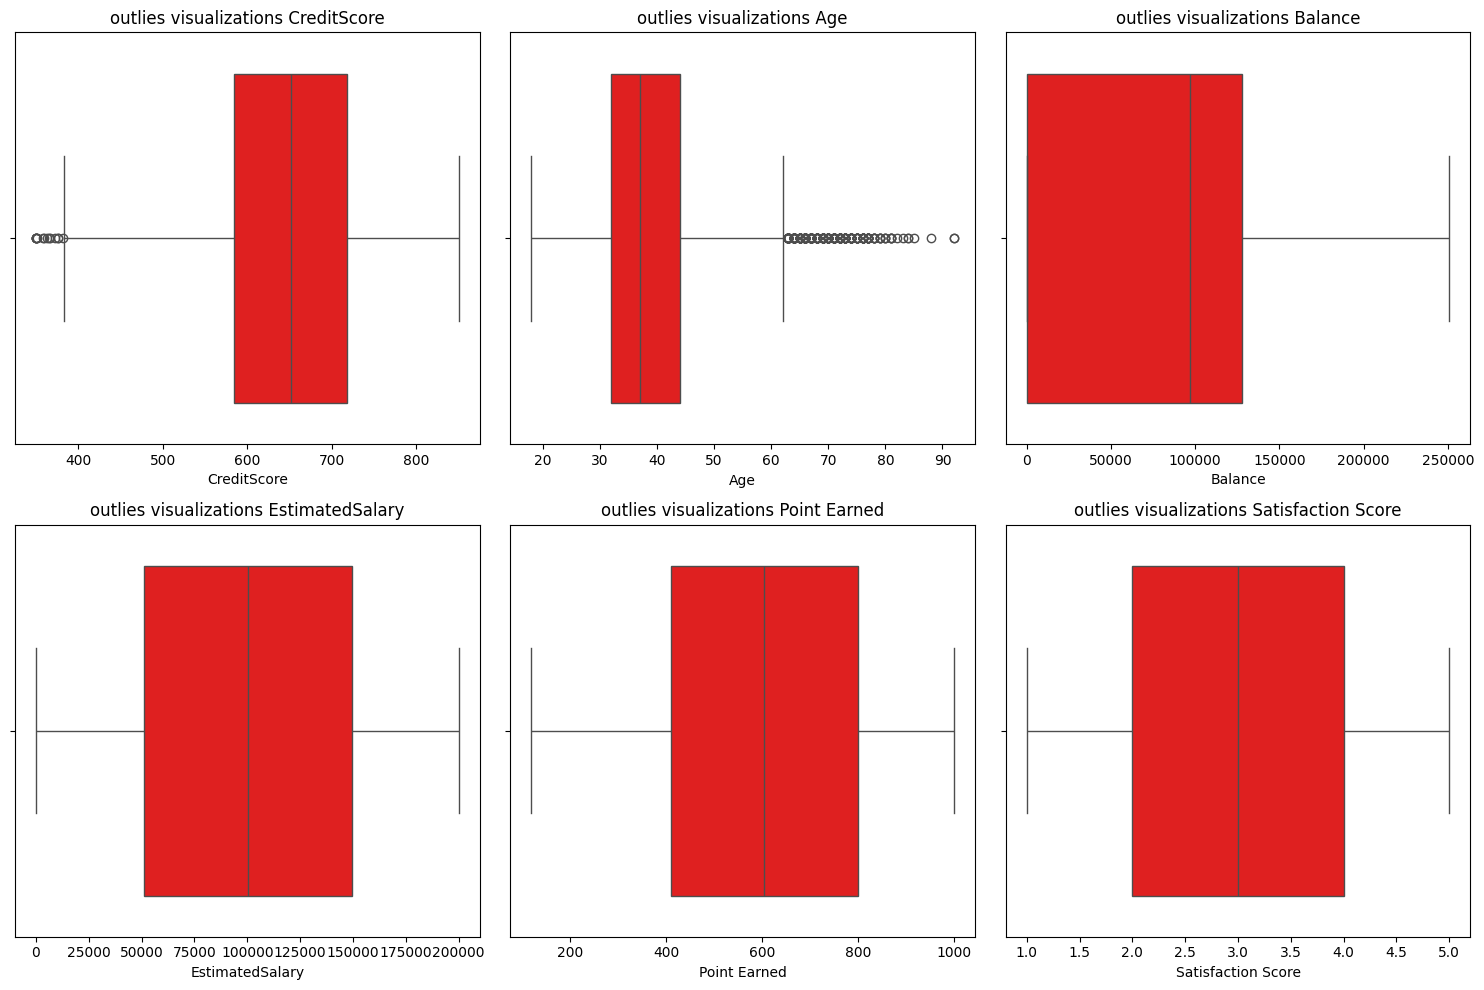

In [ ]:
# visualization of outlier in boxplot
plt.figure(figsize = (15,10))
for i , cols in enumerate(numerical_cols, 1):
  plt.subplot(2,3, i)
  sns.boxplot(x = df[cols], color = "red")
  plt.title(f"outlies visualizations {cols}")
plt.tight_layout()
plt.show()

In [ ]:
# showing also categorical columns
cat_cols = ["Geography","Gender","Card Type"]

## performing expolatory data analysis

#### performing univariate analysis
in order to understand the distributions of features and also to check whether there is  skewness/normality  of the data

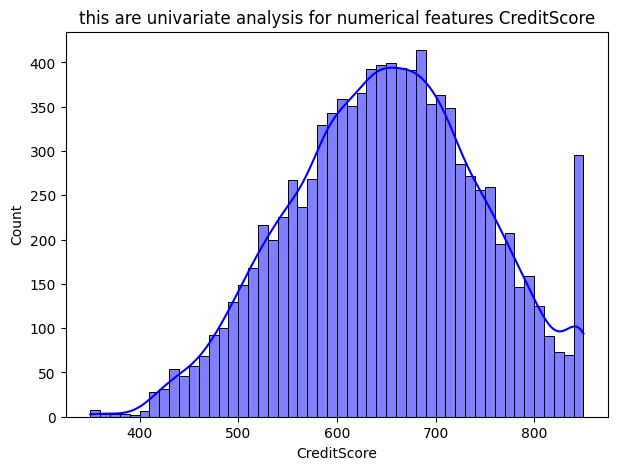

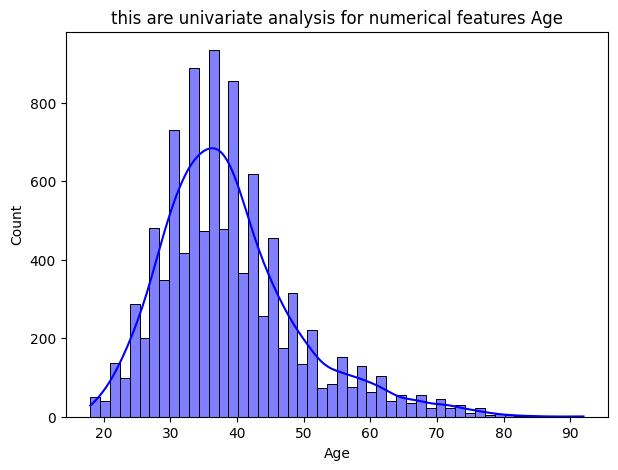

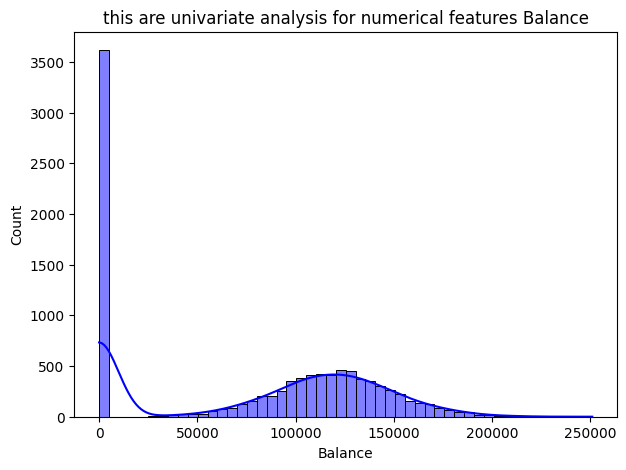

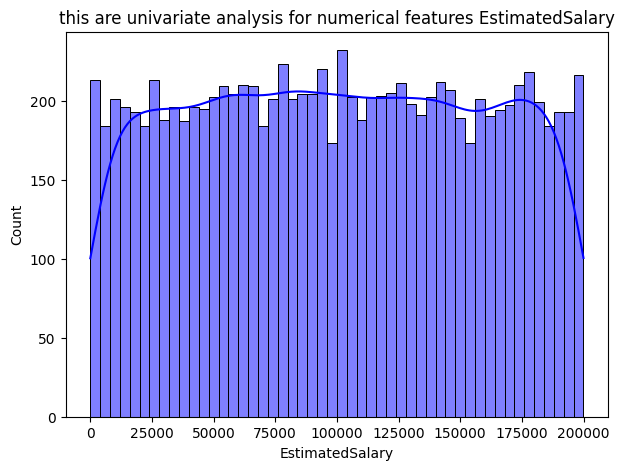

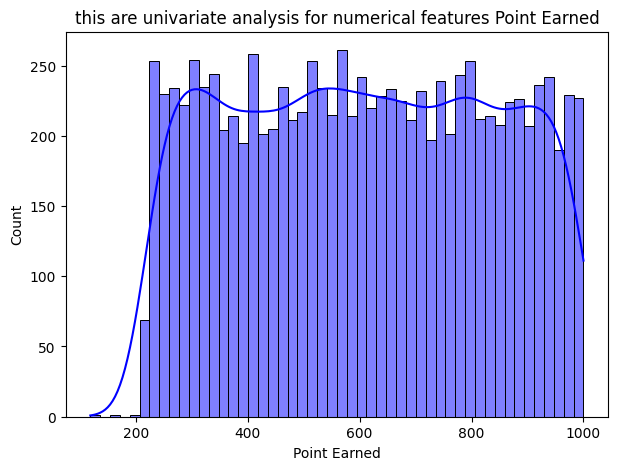

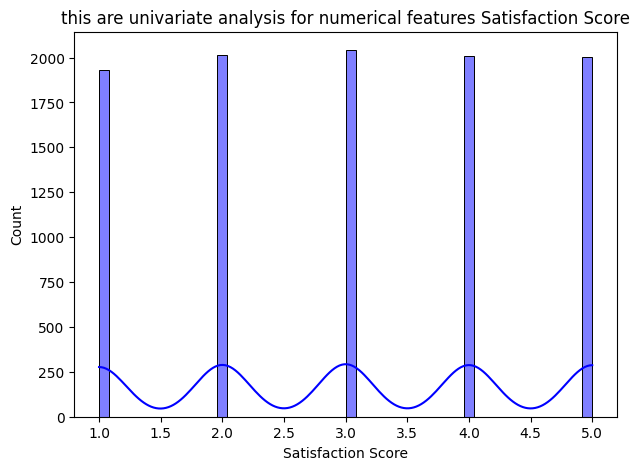

In [ ]:
# for numerical features
for cols in numerical_cols :
  plt.figure(figsize = (7,5))
  sns.histplot(df[cols], bins = 50,color = "blue",kde = True)
  plt.title(f"this are univariate analysis for numerical features {cols}")
  plt.show()

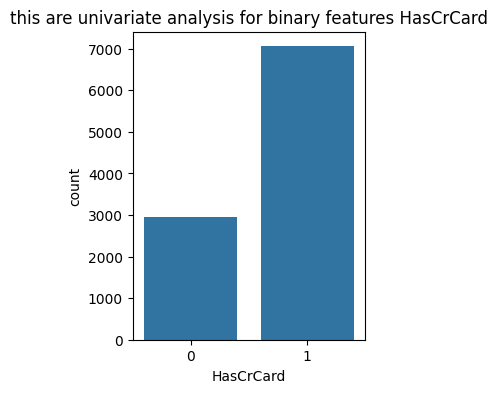

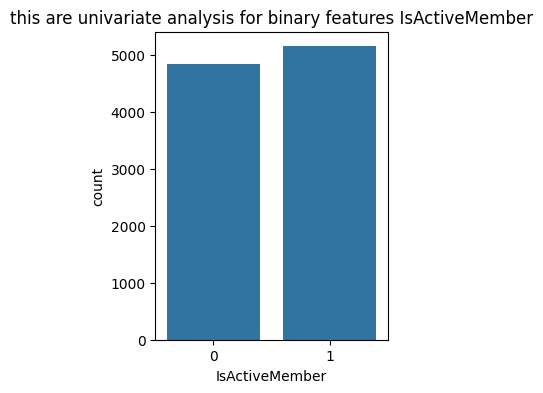

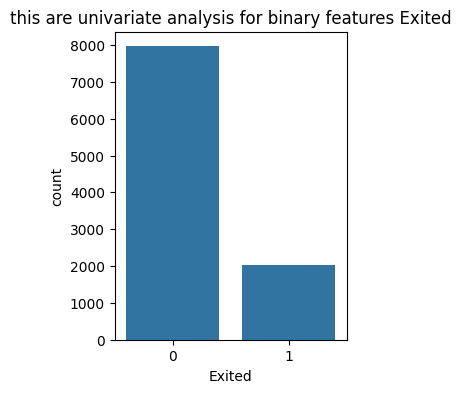

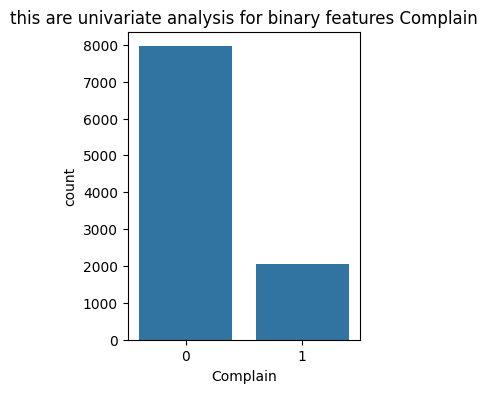

In [ ]:
# for binary features
# used to check for the imbalanced dataset
for cols in binary_cols:
  plt.figure(figsize = (3,4))
  sns.countplot(x = df[cols], )
  plt.title(f"this are univariate analysis for binary features {cols}")

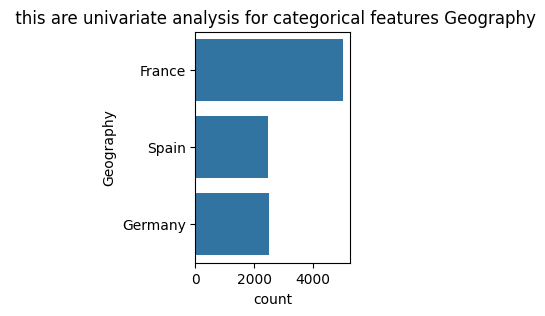

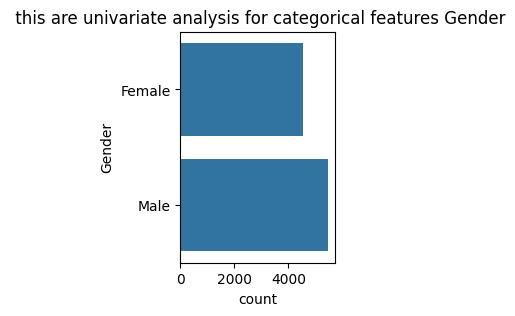

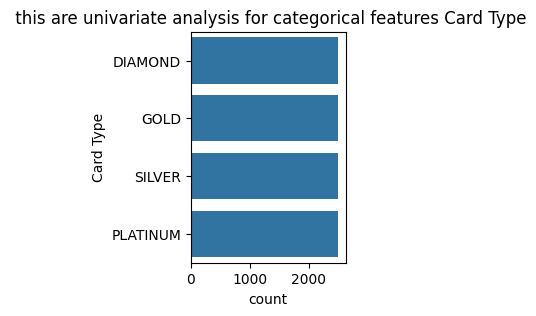

In [ ]:
# for categorical features
for cols in cat_cols:
  plt.figure(figsize = (2,3))
  sns.countplot(df[cols],)
  plt.title(f" this are univariate analysis for categorical features {cols}")
  plt.show()


#### bivariate analysis
##### in this we study the relationship between each variable and target variable
##### it reveal which feature have strong predicting power in classification

In [ ]:
df.head(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


/tmp/ipykernel_10243/1363257471.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot( x="Exited", y = "Tenure", data=df,palette = "Set1")


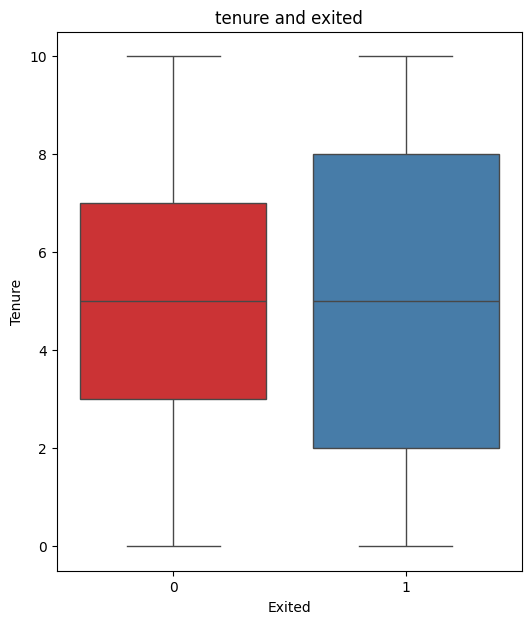

In [ ]:
plt.figure(figsize = (6,7))
sns.boxplot( x="Exited", y = "Tenure", data=df,palette = "Set1")
plt.title("tenure and exited")
plt.show()

/tmp/ipykernel_10243/465714342.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x = "Exited", y = "Age", palette = "Set1")


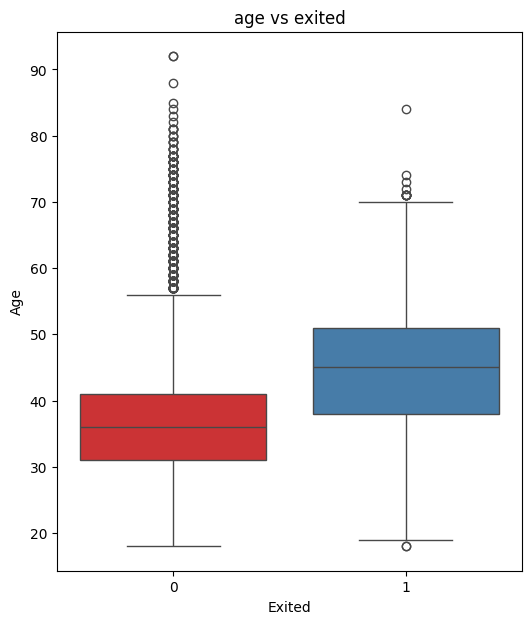

In [ ]:
plt.figure(figsize = (6,7))
sns.boxplot(data=df, x = "Exited", y = "Age", palette = "Set1")
plt.title("age vs exited")
plt.show()

/tmp/ipykernel_10243/689206719.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x = "Exited", y = "Balance", palette = "Set1")


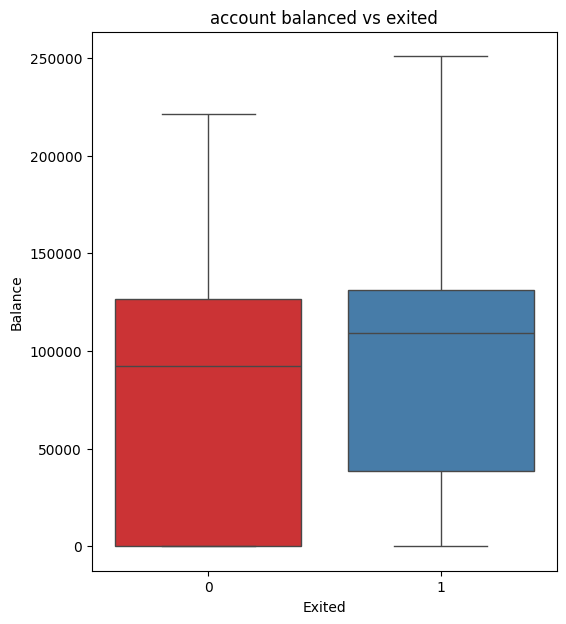

In [ ]:
plt.figure(figsize = (6,7))
sns.boxplot(data=df, x = "Exited", y = "Balance", palette = "Set1")
plt.title("account balanced vs exited")
plt.show()

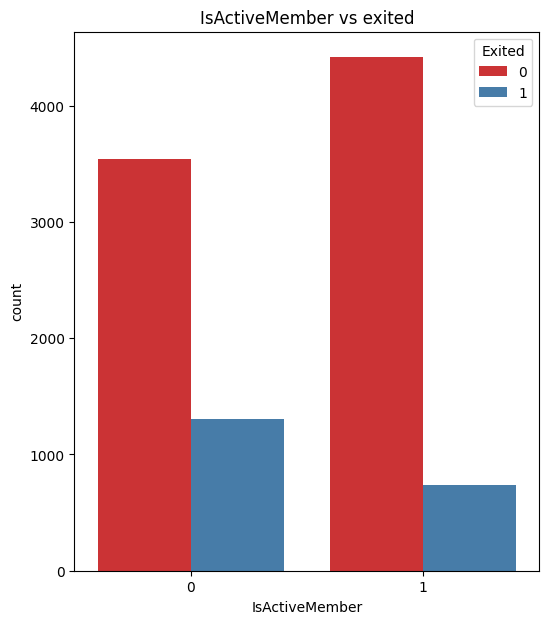

In [ ]:
plt.figure(figsize = (6,7))
sns.countplot(data=df, hue= "Exited", x = "IsActiveMember", palette = "Set1")
plt.title("IsActiveMember vs exited")
plt.show()

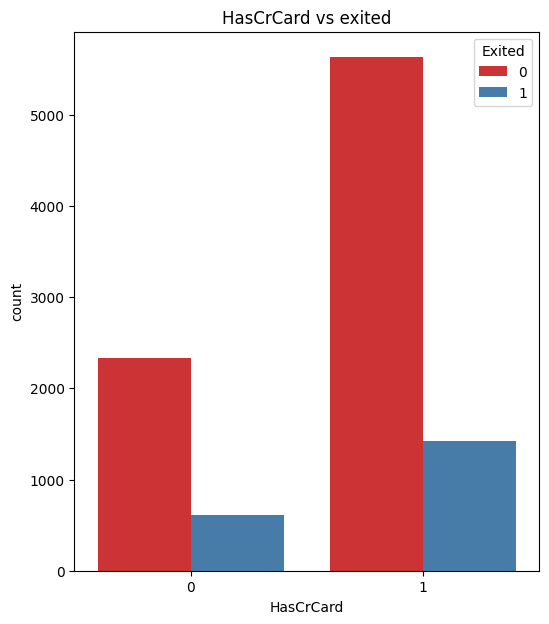

In [ ]:
plt.figure(figsize = (6,7))
sns.countplot(data=df, hue= "Exited", x = "HasCrCard", palette = "Set1")
plt.title("HasCrCard vs exited")
plt.show()

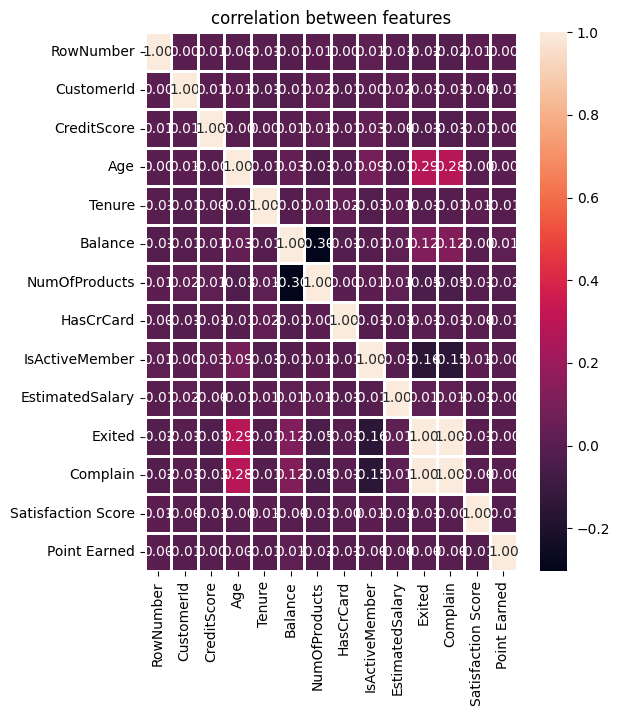

In [ ]:
plt.figure(figsize = (6,7))
df_corr = df.corr(numeric_only = True)
sns.heatmap(df_corr, annot = True, fmt = ".2f", linewidths= 2)
plt.title("correlation between features")
plt.show()


## feature engineering
#### in this is used to extract new features columns in order to increase predictivity of our model   

In [ ]:
df.head(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [ ]:
df["balance_per_col"] = df["Balance"]/df["NumOfProducts"]
round(df['balance_per_col'].sum(),2)

np.float64(628196985.3)

In [ ]:
df["balance_salary_ratio"] = df["Balance"]/df["EstimatedSalary"]
round(df["balance_salary_ratio"].sum(), 3)

np.float64(38787.029)

In [ ]:
df["age_group"] = pd.cut(df["Age"],bins=[0,30,40,60,100],labels = ["young","middle","senior","elder"])
df['age_group'].value_counts()

,count
age_group,
middle,4451
senior,3117
young,1968
elder,464


In [ ]:
df["is_high_value"] = (df['Balance']> df['Balance'].median()) & (df['IsActiveMember']== 1).astype(int)
df['is_high_value'].value_counts()

,count
is_high_value,
False,7456
True,2544


In [ ]:
print(f"New features added: Balance_Per_col, Balance_Salary_Ratio, AgeGroup, IsHighValue")
print(f"New dataset shape: {df.shape}")
df[['balance_per_col', 'balance_salary_ratio', 'age_group', 'is_high_value']].head()

New features added: Balance_Per_col, Balance_Salary_Ratio, AgeGroup, IsHighValue
New dataset shape: (10000, 22)


,balance_per_col,balance_salary_ratio,age_group,is_high_value
0,0.000000,0.000000,senior,False
1,83807.860000,0.744677,senior,False
2,53220.266667,1.401375,senior,False
3,0.000000,0.000000,middle,False
4,125510.820000,1.587055,senior,True


In [ ]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,...,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,balance_per_col,balance_salary_ratio,age_group,is_high_value
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,...,101348.88,1,1,2,DIAMOND,464,0.000000,0.000000,senior,False
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,...,112542.58,0,1,3,DIAMOND,456,83807.860000,0.744677,senior,False
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,...,113931.57,1,1,3,DIAMOND,377,53220.266667,1.401375,senior,False
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,...,93826.63,0,0,5,GOLD,350,0.000000,0.000000,middle,False
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,...,79084.10,0,0,5,GOLD,425,125510.820000,1.587055,senior,True


In [ ]:
x = df.drop(columns= ["RowNumber","CustomerId","Surname","Exited","Complain","balance_per_col",	"balance_salary_ratio","age_group","is_high_value"])

In [ ]:
x.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425


In [ ]:
x = pd.get_dummies(x, columns = ["Geography","Gender","Card Type"]).astype(int)


In [ ]:
y = df["Exited"].astype(int)

In [ ]:
x.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Point Earned,Geography_France,Geography_Germany,Geography_Spain,Gender_Female,Gender_Male,Card Type_DIAMOND,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER
0,619,42,2,0,1,1,1,101348,2,464,1,0,0,1,0,1,0,0,0
1,608,41,1,83807,1,0,1,112542,3,456,0,0,1,1,0,1,0,0,0
2,502,42,8,159660,3,1,0,113931,3,377,1,0,0,1,0,1,0,0,0
3,699,39,1,0,2,0,0,93826,5,350,1,0,0,1,0,0,1,0,0
4,850,43,2,125510,1,1,1,79084,5,425,0,0,1,1,0,0,1,0,0


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)

In [ ]:
from sklearn.preprocessing import RobustScaler,StandardScaler
scaler =StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state = 42)
x_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
model =lr.fit(x_train_smote, y_train_smote)
y_pred = model.predict(x_test)

clsr = classification_report(y_test, y_pred)
print(clsr)





              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1607
           1       0.39      0.70      0.50       393

    accuracy                           0.72      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.81      0.72      0.75      2000



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
rfc=RandomForestClassifier(max_depth=20,min_samples_leaf=1,min_samples_split=5,n_estimators=200,)
model =rfc.fit(x_train_smote, y_train_smote)
y_pred = model.predict(x_test)

clsr = classification_report(y_test, y_pred)
print(clsr)

              precision    recall  f1-score   support

           0       0.90      0.91      0.91      1607
           1       0.62      0.59      0.60       393

    accuracy                           0.85      2000
   macro avg       0.76      0.75      0.75      2000
weighted avg       0.84      0.85      0.85      2000



In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
xfc=XGBClassifier(learning_rate= 0.1, max_depth= 2, n_estimators= 400, subsample= 0.8)
model =xfc.fit(x_train_smote, y_train_smote)
y_pred = model.predict(x_test)

clsr = classification_report(y_test, y_pred)
print(clsr)
confusion_matrix(y_test,y_pred)

              precision    recall  f1-score   support

           0       0.90      0.94      0.92      1607
           1       0.69      0.58      0.63       393

    accuracy                           0.86      2000
   macro avg       0.79      0.76      0.77      2000
weighted avg       0.86      0.86      0.86      2000



array([[1504,  103],
       [ 167,  226]])

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.svm import SVC
Sfc=SVC()
model =Sfc.fit(x_train_smote, y_train_smote)
y_pred = model.predict(x_test)

clsr = classification_report(y_test, y_pred)
print(clsr)

              precision    recall  f1-score   support

           0       0.91      0.82      0.86      1607
           1       0.47      0.66      0.55       393

    accuracy                           0.79      2000
   macro avg       0.69      0.74      0.70      2000
weighted avg       0.82      0.79      0.80      2000



In [ ]:
from sklearn.model_selection import GridSearchCV
rf_model = RandomForestClassifier()

rf_params = {
    'n_estimators': [100, 200,300,400,500,600],
    'max_depth': [5, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

print(grid_rf.best_params_)
print(grid_rf.best_score_)

{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 400}
0.8630000000000001


In [ ]:
xgb_model = XGBClassifier()

xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_xgb.fit(x_train, y_train)

print(grid_xgb.best_params_)
print(grid_xgb.best_score_)

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
0.8627499999999999
